### Step 1 — Define the Causal Business Problem

Objective: Establish the treatment, outcome, target population and causal question.

In [1]:
# Step 1: Define the Causal Business Problem

experiment_name = "API Monitoring Onboarding Experiment"

treatment_group = "Treatment"
control_group = "Control"

treatment_variable = "variant"
outcome_variable = "adopted_feature"

observation_window = 7

causal_question = (
    "What is the effect of the new API Monitoring onboarding "
    "experience on 7-day feature adoption?"
)

print("CAUSAL BUSINESS PROBLEM")
print("-----------------------")

print("Experiment:", experiment_name)
print("Treatment Group:", treatment_group)
print("Control Group:", control_group)
print("Treatment Variable:", treatment_variable)
print("Outcome Variable:", outcome_variable)
print("Observation Window:", observation_window, "days")

print("\nCausal Research Question:")
print(causal_question)

CAUSAL BUSINESS PROBLEM
-----------------------
Experiment: API Monitoring Onboarding Experiment
Treatment Group: Treatment
Control Group: Control
Treatment Variable: variant
Outcome Variable: adopted_feature
Observation Window: 7 days

Causal Research Question:
What is the effect of the new API Monitoring onboarding experience on 7-day feature adoption?


### Identify Treatment and Control Groups

Objective: Define which users received the new onboarding experience and which users received the existing experience.

In [6]:
# Step 2: Identify Treatment and Control Groups

# Separate experiment groups
treatment_data = experiment_data[
    experiment_data["variant"] == "Treatment"
].copy()

control_data = experiment_data[
    experiment_data["variant"] == "Control"
].copy()

# Calculate group sizes
treatment_users = treatment_data["user_id"].nunique()
control_users = control_data["user_id"].nunique()

total_users = treatment_users + control_users

print("TREATMENT AND CONTROL GROUPS")
print("----------------------------")

print("Treatment Users:", treatment_users)
print("Control Users:", control_users)
print("Total Users:", total_users)

print("\nGroup Allocation:")

print(
    "Treatment:",
    round(treatment_users / total_users * 100, 2),
    "%"
)

print(
    "Control:",
    round(control_users / total_users * 100, 2),
    "%"
)

# Compare adoption rates
print("\nAdoption Rates:")

print(
    "Treatment:",
    round(treatment_data["adopted_feature"].mean() * 100, 2),
    "%"
)

print(
    "Control:",
    round(control_data["adopted_feature"].mean() * 100, 2),
    "%"
)

TREATMENT AND CONTROL GROUPS
----------------------------
Treatment Users: 3003
Control Users: 2997
Total Users: 6000

Group Allocation:
Treatment: 50.05 %
Control: 49.95 %

Adoption Rates:
Treatment: 64.97 %
Control: 45.85 %


#### Load the Experiment Datasets

In [4]:
# Step 2.1: Load Existing Experiment Data

import pandas as pd
from pathlib import Path

# Define project directory
project_root = Path(
    r"C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics"
)

# Define dataset paths
assignments_path = (
    project_root / "data" / "synthetic" / "experiment_assignments.csv"
)

outcomes_path = (
    project_root / "data" / "synthetic" / "experiment_outcomes.csv"
)

# Load datasets
assignments = pd.read_csv(assignments_path)
outcomes = pd.read_csv(outcomes_path)

print("Assignments Shape:", assignments.shape)
print("Outcomes Shape:", outcomes.shape)

Assignments Shape: (6000, 5)
Outcomes Shape: (6000, 8)


#### Step 2.2 — Recreate the Experiment Dataset

In [5]:
# Step 2.2: Merge Assignment and Outcome Data

experiment_data = assignments.merge(
    outcomes,
    on=["assignment_id", "user_id"],
    how="inner",
    validate="one_to_one"
)

print("Experiment Dataset Shape:", experiment_data.shape)

display(experiment_data.head())

Experiment Dataset Shape: (6000, 11)


,assignment_id,experiment_id,user_id,variant,assigned_at,outcome_id,sdk_integrated,first_api_request,adopted_feature,retained_d7,measured_at
0,1,EXP_FEATURE_ONBOARDING_001,6253,Control,2025-08-05,1,1,0,1,1,2025-08-12
1,2,EXP_FEATURE_ONBOARDING_001,4685,Treatment,2026-10-30,2,0,1,1,1,2026-11-06
2,3,EXP_FEATURE_ONBOARDING_001,1732,Control,2026-10-25,3,0,0,0,0,2026-11-01
3,4,EXP_FEATURE_ONBOARDING_001,4743,Treatment,2025-10-19,4,1,1,0,0,2025-10-26
4,5,EXP_FEATURE_ONBOARDING_001,4522,Control,2024-10-07,5,1,1,0,1,2024-10-14


### Step 3 — Define Treatment, Outcome, and Covariates

Objective: Identify the variables needed for causal analysis.
- Treatment (T): Whether a user received the new onboarding experience.
- Outcome (Y): Whether the user adopted API Monitoring within seven days.
- Covariates (X): User characteristics measured before treatment that may help explain differences between users.

In [7]:
# Step 3: Load Baseline User Characteristics

users_path = (
    project_root / "data" / "synthetic" / "users.csv"
)

users = pd.read_csv(users_path)

print("Users Dataset Shape:", users.shape)
display(users.head())

Users Dataset Shape: (10000, 7)


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified
0,1,283,2025-04-03,USA,Founder,Social Media,1
1,2,591,2024-06-23,Germany,Admin,Referral,1
2,3,72,2025-12-27,Japan,Founder,Referral,1
3,4,1287,2024-12-28,Canada,Admin,Paid Ads,0
4,5,703,2025-10-14,Germany,Founder,Paid Ads,1


In [8]:
# Merge Pre-Experiment User Characteristics

causal_data = experiment_data.merge(
    users[
        [
            "user_id",
            "country",
            "user_role",
            "acquisition_channel",
            "is_verified"
        ]
    ],
    on="user_id",
    how="left",
    validate="one_to_one"
)

print("Causal Dataset Shape:", causal_data.shape)

print("\nMissing Values:")
print(
    causal_data[
        [
            "country",
            "user_role",
            "acquisition_channel",
            "is_verified"
        ]
    ].isna().sum()
)

display(causal_data.head())

Causal Dataset Shape: (6000, 15)

Missing Values:
country                0
user_role              0
acquisition_channel    0
is_verified            0
dtype: int64


,assignment_id,experiment_id,user_id,variant,assigned_at,outcome_id,sdk_integrated,first_api_request,adopted_feature,retained_d7,measured_at,country,user_role,acquisition_channel,is_verified
0,1,EXP_FEATURE_ONBOARDING_001,6253,Control,2025-08-05,1,1,0,1,1,2025-08-12,Canada,Data Analyst,Referral,0
1,2,EXP_FEATURE_ONBOARDING_001,4685,Treatment,2026-10-30,2,0,1,1,1,2026-11-06,USA,Admin,Paid Ads,1
2,3,EXP_FEATURE_ONBOARDING_001,1732,Control,2026-10-25,3,0,0,0,0,2026-11-01,Bangladesh,Developer,Social Media,1
3,4,EXP_FEATURE_ONBOARDING_001,4743,Treatment,2025-10-19,4,1,1,0,0,2025-10-26,UK,Developer,Referral,1
4,5,EXP_FEATURE_ONBOARDING_001,4522,Control,2024-10-07,5,1,1,0,1,2024-10-14,USA,Product Manager,Paid Ads,1


#### Step 3.1 — Verify Baseline Characteristics

In [9]:
# Step 3.1: Verify Baseline User Characteristics

baseline_columns = [
    "country",
    "user_role",
    "acquisition_channel",
    "is_verified"
]

print("Missing Values:")
print(causal_data[baseline_columns].isna().sum())

print("\nBlank String Values:")
for column in baseline_columns:
    blank_count = (
        causal_data[column]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

    print(f"{column}: {blank_count}")

print("\nData Types:")
print(causal_data[baseline_columns].dtypes)

print("\nFirst 10 Baseline Records:")
display(causal_data[baseline_columns].head(10))

Missing Values:
country                0
user_role              0
acquisition_channel    0
is_verified            0
dtype: int64

Blank String Values:
country: 0
user_role: 0
acquisition_channel: 0
is_verified: 0

Data Types:
country                  str
user_role                str
acquisition_channel      str
is_verified            int64
dtype: object

First 10 Baseline Records:


,country,user_role,acquisition_channel,is_verified
0,Canada,Data Analyst,Referral,0
1,USA,Admin,Paid Ads,1
2,Bangladesh,Developer,Social Media,1
3,UK,Developer,Referral,1
4,USA,Product Manager,Paid Ads,1
5,Japan,Developer,Paid Ads,1
6,Singapore,Data Analyst,Referral,1
7,Bangladesh,Product Manager,Paid Ads,1
8,Japan,Founder,Referral,1
9,UK,Product Manager,Referral,1


#### Step 3.2 — Check Baseline Characteristics by Experiment Group

In [10]:
# Step 3.2: Compare Baseline Characteristics by Group

categorical_columns = [
    "country",
    "user_role",
    "acquisition_channel"
]

for column in categorical_columns:
    print(f"\n{'=' * 55}")
    print(f"Baseline Distribution: {column}")
    print("=" * 55)

    distribution = pd.crosstab(
        causal_data[column],
        causal_data["variant"],
        normalize="columns"
    ) * 100

    display(distribution.round(2))


# Compare verification rates
verification_summary = (
    causal_data
    .groupby("variant")
    .agg(
        total_users=("user_id", "nunique"),
        verified_rate=("is_verified", "mean")
    )
    .reset_index()
)

verification_summary["verified_rate"] *= 100

print("\nVerification Rate by Experiment Group:")
display(verification_summary.round(2))


Baseline Distribution: country


variant,Control,Treatment
country,,
Bangladesh,12.68,12.05
Canada,11.75,11.69
Germany,12.55,13.52
India,14.15,12.99
Japan,12.05,13.22
Singapore,13.58,12.99
UK,10.91,11.46
USA,12.35,12.09



Baseline Distribution: user_role


variant,Control,Treatment
user_role,,
Admin,18.89,19.81
Data Analyst,20.05,19.61
Developer,20.75,19.18
Founder,19.89,20.58
Product Manager,20.42,20.81



Baseline Distribution: acquisition_channel


variant,Control,Treatment
acquisition_channel,,
Direct,18.08,19.35
Organic,18.72,18.98
Paid Ads,21.29,21.38
Referral,19.89,19.78
Social Media,22.02,20.51



Verification Rate by Experiment Group:


,variant,total_users,verified_rate
0,Control,2997,79.81
1,Treatment,3003,78.09


### Step 4 — Calculate Standardized Mean Differences (SMD)

Objective: Measure how different the baseline characteristics are between the Treatment and Control groups.

For continuous variables, SMD compares the difference in group means relative to pooled standard deviation. For binary variables, we use the pooled proportion.

For categorical variables, we'll first one-hot encode the categories and calculate SMD for each category indicator.

In [11]:
# Step 4: Calculate Standardized Mean Differences

import numpy as np
import pandas as pd

# Convert treatment assignment into binary format
causal_data["treatment"] = (
    causal_data["variant"] == "Treatment"
).astype(int)

# One-hot encode categorical baseline variables
categorical_features = [
    "country",
    "user_role",
    "acquisition_channel"
]

baseline_encoded = pd.get_dummies(
    causal_data[categorical_features],
    drop_first=False,
    dtype=int
)

# Add binary baseline variable
baseline_encoded["is_verified"] = (
    causal_data["is_verified"]
)

# Calculate SMD for each baseline feature
smd_results = []

treatment_mask = causal_data["treatment"] == 1
control_mask = causal_data["treatment"] == 0

for column in baseline_encoded.columns:

    treatment_values = baseline_encoded.loc[
        treatment_mask, column
    ]

    control_values = baseline_encoded.loc[
        control_mask, column
    ]

    treatment_mean = treatment_values.mean()
    control_mean = control_values.mean()

    pooled_sd = np.sqrt(
        (
            treatment_values.var(ddof=1) +
            control_values.var(ddof=1)
        ) / 2
    )

    if pooled_sd == 0:
        smd = 0.0
    else:
        smd = (
            treatment_mean - control_mean
        ) / pooled_sd

    smd_results.append({
        "feature": column,
        "treatment_mean": treatment_mean,
        "control_mean": control_mean,
        "smd": smd,
        "absolute_smd": abs(smd)
    })

smd_table = pd.DataFrame(smd_results)

smd_table = smd_table.sort_values(
    "absolute_smd",
    ascending=False
)

display(smd_table.round(4))

,feature,treatment_mean,control_mean,smd,absolute_smd
18,is_verified,0.7809,0.7981,-0.0423,0.0423
10,user_role_Developer,0.1918,0.2075,-0.0394,0.0394
17,acquisition_channel_Social Media,0.2051,0.2202,-0.0369,0.0369
4,country_Japan,0.1322,0.1205,0.0354,0.0354
3,country_India,0.1299,0.1415,-0.0339,0.0339
13,acquisition_channel_Direct,0.1935,0.1808,0.0324,0.0324
2,country_Germany,0.1352,0.1255,0.0289,0.0289
8,user_role_Admin,0.1981,0.1889,0.0235,0.0235
0,country_Bangladesh,0.1205,0.1268,-0.0190,0.0190
5,country_Singapore,0.1299,0.1358,-0.0175,0.0175


### Step 5 — Visualize Covariate Balance (Love Plot)

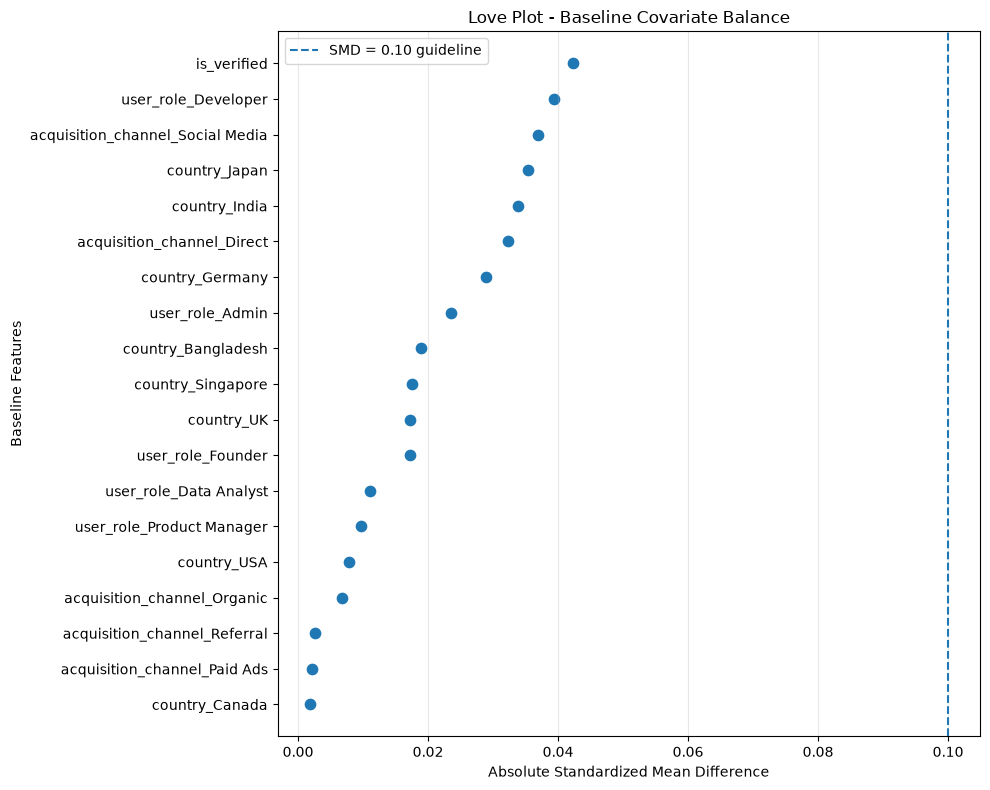

In [12]:
# Step 5: Create a Love Plot

import matplotlib.pyplot as plt

plot_data = smd_table.sort_values(
    "absolute_smd",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.scatter(
    plot_data["absolute_smd"],
    plot_data["feature"],
    s=55
)

plt.axvline(
    x=0.10,
    linestyle="--",
    label="SMD = 0.10 guideline"
)

plt.xlabel("Absolute Standardized Mean Difference")
plt.ylabel("Baseline Features")
plt.title("Love Plot - Baseline Covariate Balance")

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Step 6 — Estimate Propensity Scores

Objective: Estimate each user's probability of receiving the Treatment group based on their observed baseline characteristics.

We will use logistic regression to estimate propensity scores. These scores can later support a matching exercise.

In [13]:

# Step 6: Estimate Propensity Scores

import statsmodels.api as sm
import pandas as pd

# Define baseline covariates
propensity_features = [
    "country",
    "user_role",
    "acquisition_channel",
    "is_verified"
]

# One-hot encode categorical variables
X_ps = pd.get_dummies(
    causal_data[propensity_features],
    columns=["country", "user_role", "acquisition_channel"],
    drop_first=True,
    dtype=int
)

# Ensure all predictors are numeric
X_ps = X_ps.astype(float)

# Add intercept
X_ps = sm.add_constant(X_ps)

# Treatment assignment
treatment = causal_data["treatment"]

# Fit logistic regression
propensity_model = sm.Logit(
    treatment,
    X_ps
).fit(disp=False)

# Estimate propensity scores
causal_data["propensity_score"] = propensity_model.predict(X_ps)

print("Propensity score model fitted successfully.")

print("\nPropensity Score Summary:")
display(
    causal_data["propensity_score"].describe().round(4)
)

print("\nFirst 10 Propensity Scores:")
display(
    causal_data[
        ["user_id", "variant", "propensity_score"]
    ].head(10)
)


Propensity score model fitted successfully.

Propensity Score Summary:


count    6000.0000
mean        0.5005
std         0.0243
min         0.4367
25%         0.4833
50%         0.4995
75%         0.5176
max         0.5711
Name: propensity_score, dtype: float64


First 10 Propensity Scores:


,user_id,variant,propensity_score
0,6253,Control,0.515579
1,4685,Treatment,0.502712
2,1732,Control,0.445186
3,4743,Treatment,0.485407
4,4522,Control,0.496294
5,6341,Control,0.499322
6,577,Control,0.478106
7,5203,Control,0.487990
8,6364,Control,0.525366
9,440,Control,0.510375


### Step 7 — Visualize Propensity Score Distribution

Objective: Compare propensity score distributions between Treatment and Control groups and check whether they overlap

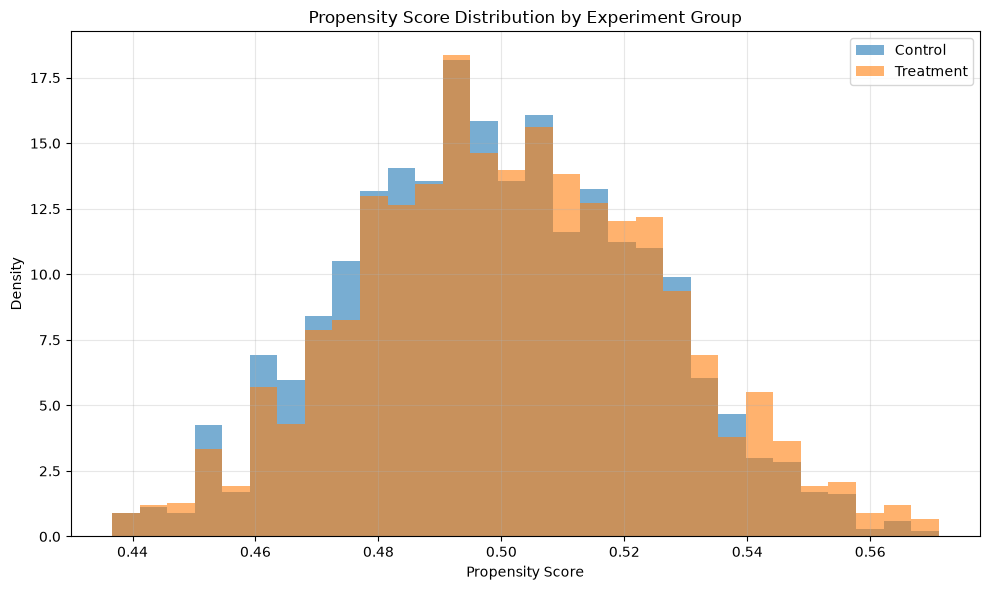

In [14]:

# Step 7: Visualize Propensity Score Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    causal_data.loc[
        causal_data["variant"] == "Control",
        "propensity_score"
    ],
    bins=30,
    alpha=0.6,
    label="Control",
    density=True
)

plt.hist(
    causal_data.loc[
        causal_data["variant"] == "Treatment",
        "propensity_score"
    ],
    bins=30,
    alpha=0.6,
    label="Treatment",
    density=True
)

plt.xlabel("Propensity Score")
plt.ylabel("Density")
plt.title("Propensity Score Distribution by Experiment Group")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 8 — Perform Propensity Score Matching (PSM)

Objective: Match each Treatment user with a similar Control user based on their estimated propensity scores.

We'll use 1:1 nearest-neighbor matching without replacement. This means each Treatment user will be matched to one Control user with the closest propensity score, and a Control user cannot be reused.

In [15]:

# Step 8: Perform 1:1 Propensity Score Matching

from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

# Separate treatment and control users
treatment_users = causal_data[
    causal_data["treatment"] == 1
].copy()

control_users = causal_data[
    causal_data["treatment"] == 0
].copy()

# Sort both groups by propensity score
treatment_users = treatment_users.sort_values(
    "propensity_score"
).reset_index(drop=True)

control_users = control_users.sort_values(
    "propensity_score"
).reset_index(drop=True)

# Initialize nearest-neighbor model
nearest_neighbors = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean"
)

# Fit using control propensity scores
nearest_neighbors.fit(
    control_users[["propensity_score"]]
)

# Find nearest control for each treatment user
distances, indices = nearest_neighbors.kneighbors(
    treatment_users[["propensity_score"]]
)

# Create candidate matches
matches = pd.DataFrame({
    "treatment_user_id": treatment_users["user_id"].values,
    "control_user_id": control_users.iloc[indices.flatten()]["user_id"].values,
    "treatment_score": treatment_users["propensity_score"].values,
    "control_score": control_users.iloc[indices.flatten()]["propensity_score"].values,
    "distance": distances.flatten()
})

# Keep each control user only once:
# process closest candidate pairs first
matches = matches.sort_values(
    "distance"
).drop_duplicates(
    subset="control_user_id",
    keep="first"
).reset_index(drop=True)

print("Propensity score matching completed.")

print("\nMatching Summary:")
print("Treatment users:", len(treatment_users))
print("Available control users:", len(control_users))
print("Matched pairs:", len(matches))
print("Unmatched treatment users:", len(treatment_users) - len(matches))

print("\nFirst 10 Matched Pairs:")
display(matches.head(10).round(5))


Propensity score matching completed.

Matching Summary:
Treatment users: 3003
Available control users: 2997
Matched pairs: 387
Unmatched treatment users: 2616

First 10 Matched Pairs:


,treatment_user_id,control_user_id,treatment_score,control_score,distance
0,758,6686,0.44664,0.44664,0.0
1,7631,1627,0.55990,0.55990,0.0
2,5995,2421,0.56343,0.56343,0.0
3,1515,4396,0.56483,0.56483,0.0
4,5744,6532,0.56621,0.56621,0.0
5,7416,4751,0.56835,0.56835,0.0
6,2499,1562,0.43666,0.43666,0.0
7,9649,2993,0.44519,0.44519,0.0
8,9166,5216,0.45202,0.45202,0.0
9,7994,4565,0.45256,0.45256,0.0


### Step 8 — Correct the Propensity Score Matching

In [16]:

# Step 8: Correct 1:1 Propensity Score Matching Without Replacement

import numpy as np
import pandas as pd

# Separate treatment and control users
treatment_users = (
    causal_data[causal_data["treatment"] == 1]
    .sort_values("propensity_score")
    .reset_index(drop=True)
)

control_users = (
    causal_data[causal_data["treatment"] == 0]
    .sort_values("propensity_score")
    .reset_index(drop=True)
)

# Store available control positions
available_control_positions = np.arange(len(control_users))

matched_pairs = []

# Process treatment users in ascending propensity-score order
for _, treatment_row in treatment_users.iterrows():

    if len(available_control_positions) == 0:
        break

    treatment_score = treatment_row["propensity_score"]

    # Scores of controls that have not yet been matched
    available_scores = control_users.loc[
        available_control_positions,
        "propensity_score"
    ].to_numpy()

    # Find the closest available control
    nearest_position = np.argmin(
        np.abs(available_scores - treatment_score)
    )

    control_position = available_control_positions[nearest_position]
    control_row = control_users.iloc[control_position]

    distance = abs(
        treatment_score - control_row["propensity_score"]
    )

    matched_pairs.append({
        "treatment_user_id": treatment_row["user_id"],
        "control_user_id": control_row["user_id"],
        "treatment_score": treatment_score,
        "control_score": control_row["propensity_score"],
        "distance": distance
    })

    # Remove the selected control user
    available_control_positions = np.delete(
        available_control_positions,
        nearest_position
    )

# Create matching DataFrame
matches = pd.DataFrame(matched_pairs)

print("Corrected propensity score matching completed.")

print("\nMatching Summary:")
print("Treatment users:", len(treatment_users))
print("Available control users:", len(control_users))
print("Matched pairs:", len(matches))
print("Unmatched treatment users:", len(treatment_users) - len(matches))
print("Unique matched control users:", matches["control_user_id"].nunique())

print("\nMatching Distance Summary:")
display(matches["distance"].describe().round(6))

print("\nFirst 10 Matched Pairs:")
display(matches.head(10).round(6))


Corrected propensity score matching completed.

Matching Summary:
Treatment users: 3003
Available control users: 2997
Matched pairs: 2997
Unmatched treatment users: 6
Unique matched control users: 2997

Matching Distance Summary:


count    2997.000000
mean        0.003955
std         0.015681
min         0.000000
25%         0.000000
50%         0.000264
75%         0.001092
max         0.115793
Name: distance, dtype: float64


First 10 Matched Pairs:


,treatment_user_id,control_user_id,treatment_score,control_score,distance
0,7260,1562,0.436657,0.436657,0.0
1,2499,7252,0.436657,0.436657,0.0
2,9507,5097,0.436657,0.436657,0.0
3,4783,3097,0.436657,0.436657,0.0
4,403,8375,0.436657,0.436657,0.0
5,2295,8333,0.436657,0.436657,0.0
6,5083,2759,0.436657,0.436657,0.0
7,7039,7149,0.436657,0.436657,0.0
8,3602,2227,0.436657,0.436657,0.0
9,15,8597,0.436657,0.436657,0.0


### Step 9 — Apply a Propensity Score Caliper

Objective: Remove pairs whose propensity score distance is too large.

In [17]:

# Step 9: Apply Propensity Score Caliper

caliper = 0.05

# Keep only pairs within the caliper
matched_data = matches[
    matches["distance"] <= caliper
].copy()

matched_data = matched_data.reset_index(drop=True)

print("Caliper:", caliper)

print("\nCaliper Matching Summary:")
print("Original matched pairs:", len(matches))
print("Pairs retained:", len(matched_data))
print("Pairs removed:", len(matches) - len(matched_data))
print("Treatment users retained:", len(matched_data))
print("Control users retained:", matched_data["control_user_id"].nunique())

print("\nMatching Distance After Caliper:")
display(matched_data["distance"].describe().round(6))

print("\nFirst 10 Retained Pairs:")
display(matched_data.head(10).round(6))


Caliper: 0.05

Caliper Matching Summary:
Original matched pairs: 2997
Pairs retained: 2885
Pairs removed: 112
Treatment users retained: 2885
Control users retained: 2885

Matching Distance After Caliper:


count    2885.000000
mean        0.000966
std         0.002611
min         0.000000
25%         0.000000
50%         0.000225
75%         0.000988
max         0.046237
Name: distance, dtype: float64


First 10 Retained Pairs:


,treatment_user_id,control_user_id,treatment_score,control_score,distance
0,7260,1562,0.436657,0.436657,0.0
1,2499,7252,0.436657,0.436657,0.0
2,9507,5097,0.436657,0.436657,0.0
3,4783,3097,0.436657,0.436657,0.0
4,403,8375,0.436657,0.436657,0.0
5,2295,8333,0.436657,0.436657,0.0
6,5083,2759,0.436657,0.436657,0.0
7,7039,7149,0.436657,0.436657,0.0
8,3602,2227,0.436657,0.436657,0.0
9,15,8597,0.436657,0.436657,0.0


### Step 10 — Evaluate Covariate Balance After Matching

In [18]:

# Step 10: Evaluate Covariate Balance After Matching

# Retrieve matched treatment and control records
matched_treatment = (
    causal_data.set_index("user_id")
    .loc[matched_data["treatment_user_id"]]
    .reset_index()
)

matched_control = (
    causal_data.set_index("user_id")
    .loc[matched_data["control_user_id"]]
    .reset_index()
)

# Encode baseline covariates consistently
baseline_columns = [
    "country",
    "user_role",
    "acquisition_channel",
    "is_verified"
]

matched_encoded = pd.get_dummies(
    pd.concat(
        [matched_treatment[baseline_columns],
         matched_control[baseline_columns]],
        ignore_index=True
    ),
    columns=["country", "user_role", "acquisition_channel"],
    drop_first=False,
    dtype=int
)

# Separate treatment and control encoded rows
n_pairs = len(matched_treatment)

treatment_encoded = matched_encoded.iloc[:n_pairs]
control_encoded = matched_encoded.iloc[n_pairs:]

# Calculate standardized mean differences
balance_results = []

for column in matched_encoded.columns:

    treatment_values = treatment_encoded[column]
    control_values = control_encoded[column]

    treatment_mean = treatment_values.mean()
    control_mean = control_values.mean()

    pooled_sd = np.sqrt(
        (
            treatment_values.var(ddof=1)
            + control_values.var(ddof=1)
        ) / 2
    )

    smd = (
        (treatment_mean - control_mean) / pooled_sd
        if pooled_sd > 0 else 0.0
    )

    balance_results.append({
        "feature": column,
        "treatment_mean": treatment_mean,
        "control_mean": control_mean,
        "smd": smd,
        "absolute_smd": abs(smd)
    })

matched_balance = pd.DataFrame(balance_results).sort_values(
    "absolute_smd",
    ascending=False
)

display(matched_balance.round(4))

print("\nBalance Summary:")
print(
    "Features with absolute SMD below 0.10:",
    (matched_balance["absolute_smd"] < 0.10).sum()
)
print("Total features:", len(matched_balance))
print(
    "Maximum absolute SMD:",
    round(matched_balance["absolute_smd"].max(), 4)
)


,feature,treatment_mean,control_mean,smd,absolute_smd
0,is_verified,0.8107,0.7927,0.0452,0.0452
5,country_Japan,0.1165,0.1251,-0.0266,0.0266
2,country_Canada,0.1206,0.1140,0.0205,0.0205
10,user_role_Data Analyst,0.2021,0.1945,0.0191,0.0191
18,acquisition_channel_Social Media,0.2135,0.2062,0.0179,0.0179
11,user_role_Developer,0.1997,0.2052,-0.0138,0.0138
1,country_Bangladesh,0.1255,0.1210,0.0137,0.0137
14,acquisition_channel_Direct,0.1827,0.1879,-0.0134,0.0134
4,country_India,0.1352,0.1386,-0.0101,0.0101
15,acquisition_channel_Organic,0.1889,0.1927,-0.0097,0.0097



Balance Summary:
Features with absolute SMD below 0.10: 19
Total features: 19
Maximum absolute SMD: 0.0452


### Step 11 — Calculate the Matched Treatment Effect

Objective: Compare 7-day feature adoption between the matched Treatment and Control users.

In [19]:

# Step 11: Calculate Matched Treatment Effect

# Retrieve outcomes for matched users
matched_treatment_outcomes = (
    causal_data.set_index("user_id")
    .loc[matched_data["treatment_user_id"]]
    .reset_index()
)

matched_control_outcomes = (
    causal_data.set_index("user_id")
    .loc[matched_data["control_user_id"]]
    .reset_index()
)

# Calculate adoption rates
treatment_adoption_rate = (
    matched_treatment_outcomes["adopted_feature"].mean()
)

control_adoption_rate = (
    matched_control_outcomes["adopted_feature"].mean()
)

# Calculate treatment effect
absolute_effect = (
    treatment_adoption_rate - control_adoption_rate
)

relative_lift = (
    absolute_effect / control_adoption_rate
) * 100

# Display results
matched_effect_summary = pd.DataFrame({
    "Group": ["Treatment", "Control"],
    "Users": [
        len(matched_treatment_outcomes),
        len(matched_control_outcomes)
    ],
    "Adopters": [
        matched_treatment_outcomes["adopted_feature"].sum(),
        matched_control_outcomes["adopted_feature"].sum()
    ],
    "Adoption Rate (%)": [
        treatment_adoption_rate * 100,
        control_adoption_rate * 100
    ]
})

display(matched_effect_summary.round(2))

print("\nMatched Treatment Effect:")
print(f"Absolute Effect: {absolute_effect * 100:.2f} percentage points")
print(f"Relative Lift: {relative_lift:.2f}%")


,Group,Users,Adopters,Adoption Rate (%)
0,Treatment,2885,1867,64.71
1,Control,2885,1320,45.75



Matched Treatment Effect:
Absolute Effect: 18.96 percentage points
Relative Lift: 41.44%


### Step 12 — Calculate the 95% Confidence Interval

Objective: Estimate the uncertainty around the matched adoption-rate difference.

In [21]:

# Step 12: Calculate Paired 95% Confidence Interval

from scipy import stats
import numpy as np

# Create paired adoption outcomes
paired_results = pd.DataFrame({
    "treatment_adopted": matched_treatment_outcomes[
        "adopted_feature"
    ].to_numpy(),
    "control_adopted": matched_control_outcomes[
        "adopted_feature"
    ].to_numpy()
})

# Calculate within-pair differences
paired_results["difference"] = (
    paired_results["treatment_adopted"]
    - paired_results["control_adopted"]
)

# Mean paired difference
mean_difference = paired_results["difference"].mean()

# Standard error of paired differences
standard_error = (
    paired_results["difference"].std(ddof=1)
    / np.sqrt(len(paired_results))
)

# 95% t-based confidence interval
degrees_of_freedom = len(paired_results) - 1

critical_value = stats.t.ppf(
    0.975,
    degrees_of_freedom
)

ci_lower = mean_difference - critical_value * standard_error
ci_upper = mean_difference + critical_value * standard_error

print("Paired Confidence Interval Results")
print("-----------------------------------")
print(f"Matched pairs: {len(paired_results)}")
print(f"Mean difference: {mean_difference * 100:.2f} percentage points")
print(f"Standard error: {standard_error * 100:.4f} percentage points")
print(
    f"95% Confidence Interval: "
    f"[{ci_lower * 100:.2f}, {ci_upper * 100:.2f}] percentage points"
)


Paired Confidence Interval Results
-----------------------------------
Matched pairs: 2885
Mean difference: 18.96 percentage points
Standard error: 1.2725 percentage points
95% Confidence Interval: [16.47, 21.46] percentage points


### Step 13 — Perform McNemar's Test

In [22]:

# Step 13: Perform McNemar's Test

from scipy.stats import binomtest

# Create paired outcome contingency table
contingency_table = pd.crosstab(
    paired_results["treatment_adopted"],
    paired_results["control_adopted"]
)

contingency_table = contingency_table.reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0
)

print("Paired Outcome Contingency Table:")
print(contingency_table)

# Discordant pairs:
# Treatment adopted, Control did not adopt
treatment_only = contingency_table.loc[1, 0]

# Control adopted, Treatment did not adopt
control_only = contingency_table.loc[0, 1]

discordant_pairs = treatment_only + control_only

# Exact two-sided McNemar test using the binomial distribution
mcnemar_result = binomtest(
    k=int(treatment_only),
    n=int(discordant_pairs),
    p=0.5,
    alternative="two-sided"
)

print("\nMcNemar Test Results")
print("--------------------")
print("Treatment-only adopters:", treatment_only)
print("Control-only adopters:", control_only)
print("Total discordant pairs:", discordant_pairs)
print(f"Exact McNemar p-value: {mcnemar_result.pvalue:.10f}")

alpha = 0.05

if mcnemar_result.pvalue < alpha:
    print("\nResult: Statistically significant difference.")
else:
    print("\nResult: No statistically significant difference.")


Paired Outcome Contingency Table:
control_adopted      0    1
treatment_adopted          
0                  566  452
1                  999  868

McNemar Test Results
--------------------
Treatment-only adopters: 999
Control-only adopters: 452
Total discordant pairs: 1451
Exact McNemar p-value: 0.0000000000

Result: Statistically significant difference.


### Step 14 — Visualize Matched Treatment Effect

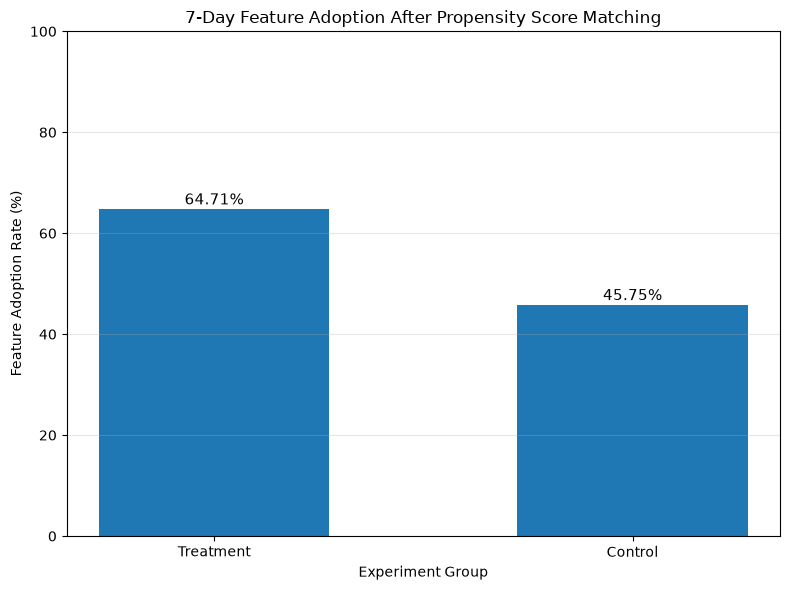

In [23]:

# Step 14: Visualize Matched Treatment Effect

import matplotlib.pyplot as plt

groups = ["Treatment", "Control"]

adoption_rates = [
    treatment_adoption_rate * 100,
    control_adoption_rate * 100
]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    groups,
    adoption_rates,
    width=0.55
)

plt.ylabel("Feature Adoption Rate (%)")
plt.xlabel("Experiment Group")
plt.title("7-Day Feature Adoption After Propensity Score Matching")

plt.ylim(0, 100)

# Add percentage labels
for bar, rate in zip(bars, adoption_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.2f}%",
        ha="center",
        fontsize=11
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Step 15 — Document Causal Impact Analysis Findings

Objective: Save the methodology, statistical results, business interpretation, and limitations in your project documentation folder.

In [24]:

# Step 15: Create Causal Impact Analysis Report

from pathlib import Path

documentation_path = (
    project_root / "python" / "documentation"
)

documentation_path.mkdir(
    parents=True,
    exist_ok=True
)

report_path = (
    documentation_path / "CAUSAL_IMPACT_ANALYSIS_REPORT.md"
)

report_content = """
# Causal Impact Analysis Report

## 1. Project Overview

Project: AI-Powered Feature Adoption Prediction & Causal Impact Analysis for Developer Tools

Experiment: API Monitoring Onboarding Experiment

Experiment ID: EXP_FEATURE_ONBOARDING_001

Objective:
Evaluate the relationship between the new API Monitoring onboarding
experience and 7-day feature adoption.

## 2. Causal Business Question

What is the effect of the new API Monitoring onboarding experience
on 7-day feature adoption?

Treatment group: Treatment

Control group: Control

Treatment variable: variant

Outcome variable: adopted_feature

Observation window: 7 days

## 3. Baseline Covariates

The propensity score model used these observed baseline characteristics:

- Country
- User role
- Acquisition channel
- Verification status

Categorical variables were one-hot encoded.

## 4. Baseline Covariate Balance

Standardized Mean Differences (SMD) were calculated before matching.

All 19 encoded baseline features had absolute SMD values below 0.10.

This indicated good observed baseline balance before matching.

## 5. Propensity Score Estimation

A logistic regression model estimated each user's probability
of receiving the Treatment group based on observed baseline covariates.

Propensity score summary:

- Users: 6,000
- Mean: 0.5005
- Standard deviation: 0.0243
- Minimum: 0.4367
- Maximum: 0.5711

## 6. Propensity Score Matching

Method: 1:1 greedy nearest-neighbor matching without replacement.

Caliper: 0.05

Matching results:

- Treatment users: 3,003
- Control users: 2,997
- Initial matched pairs: 2,997
- Pairs retained after caliper: 2,885
- Unmatched Treatment users after caliper: 118

## 7. Covariate Balance After Matching

All 19 encoded baseline features had absolute SMD values below 0.10.

Maximum absolute SMD: 0.0452

This indicates good balance across the measured baseline covariates
in the retained matched sample.

## 8. Matched Treatment Effect

Treatment group:

- Matched users: 2,885
- Feature adopters: 1,867
- Adoption rate: 64.71%

Control group:

- Matched users: 2,885
- Feature adopters: 1,320
- Adoption rate: 45.75%

Absolute adoption-rate difference: +18.96 percentage points

Relative lift: +41.44%

## 9. Confidence Interval

An approximate paired 95% t-based confidence interval was calculated
using within-pair differences.

- Mean difference: 18.96 percentage points
- Standard error: 1.2725 percentage points
- Lower bound: 16.47 percentage points
- Upper bound: 21.46 percentage points

This interval does not account for uncertainty from propensity score
estimation and the matching procedure.

## 10. McNemar's Test

Paired outcome counts:

- Both did not adopt: 566
- Treatment adopted, Control did not: 999
- Control adopted, Treatment did not: 452
- Both adopted: 868

Exact two-sided McNemar test:

- Discordant pairs: 1,451
- p-value: approximately 1.03e-47

The paired adoption outcomes showed a statistically significant
difference between the two groups.

## 11. Business Interpretation

In the matched sample, the Treatment group had a 7-day feature
adoption rate of 64.71%, compared with 45.75% in the Control group.

The observed difference was 18.96 percentage points.

This suggests that the new onboarding experience is associated
with substantially higher feature adoption among the matched users.

## 12. Limitations

- The experiment's randomization mechanism was not independently verified.
- Propensity score matching adjusts only for observed baseline covariates.
- Unmeasured confounding may remain.
- The matching procedure used greedy nearest-neighbor matching,
  not globally optimal matching.
- The confidence interval does not account for propensity score
  estimation and matching uncertainty.
- Statistical significance alone does not establish causality.

Therefore, these findings should be interpreted as an adjusted
matched-sample association rather than definitive causal evidence.

## 13. Conclusion

The matched analysis found a 18.96 percentage-point difference
in 7-day feature adoption between Treatment and Control users.

The measured baseline covariates were well balanced after matching,
and McNemar's test indicated a statistically significant difference.

Further validation of the assignment mechanism and experimental
design is required before making a definitive causal claim.
"""

report_path.write_text(
    report_content,
    encoding="utf-8"
)

print("Causal Impact Analysis report created successfully.")
print("Report location:", report_path)
print("File exists:", report_path.exists())


Causal Impact Analysis report created successfully.
Report location: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\documentation\CAUSAL_IMPACT_ANALYSIS_REPORT.md
File exists: True
